# 01 · Data exploration

Load the labels, check their integrity, clean them, and look at class balance.

**Needs:** `data/train_labels.csv`  
**Writes:** nothing (exploration only)

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Find the project root (the folder holding pyproject.toml) and make src/ importable.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from melanoma_detection.utils import RANDOM_STATE, get_project_paths, setup_logging
from melanoma_detection import data
setup_logging()
P = get_project_paths(ROOT)   # edit get_project_paths(ROOT, data_dir=...) if your data lives elsewhere
print("Project root:", P.root)

Project root: C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma


## Load and check

In [2]:
raw = data.load_labels(P.labels)
print(f"{len(raw):,} rows, {raw['patient_id'].nunique():,} patients")

display(data.check_record_integrity(raw).to_frame("problems (should all be 0)"))
display(data.summarise_missingness(raw).round(2))

6,864 rows, 422 patients


,problems (should all be 0)
duplicate rows,0
duplicate image IDs,0
"target values outside {0, 1}",0
ages outside 0-120,0


,missing_records,missing_record_percent,unique_values
image_name,0,0.00,6864
patient_id,0,0.00,422
sex,0,0.00,2
age_approx,0,0.00,16
anatom_site_general_challenge,196,2.86,6
diagnosis,0,0.00,8
benign_malignant,0,0.00,2
target,0,0.00,2


## Clean and build the patient table

In [3]:
clean = data.clean_train_labels(raw)
patients = data.build_patient_table(clean)

display(clean.head())
print(f"{len(patients):,} patients | median {patients['image_count'].median():.0f} images per patient")

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,site_missing
0,ISIC_0015719,IP_3075186,female,45,upper extremity,unknown,benign,0,0
1,ISIC_0074542,IP_4698288,male,25,lower extremity,unknown,benign,0,0
2,ISIC_0076545,IP_9802602,male,55,upper extremity,unknown,benign,0,0
3,ISIC_0082348,IP_7684360,male,55,torso,unknown,benign,0,0
4,ISIC_0085172,IP_1705144,female,50,lower extremity,unknown,benign,0,0


422 patients | median 12 images per patient


## Class balance

Melanoma is rare, so accuracy alone is misleading. This is why later notebooks use a weighted loss and report recall, specificity and average precision.

In [4]:
image_counts = clean["target"].value_counts().sort_index()
patient_counts = patients["has_malignant"].value_counts().sort_index()

balance = pd.DataFrame({
    "images": image_counts,
    "patients (any malignant image)": patient_counts,
})
balance.index = ["Non-melanoma / no melanoma", "Melanoma"]
display(balance)
print(f"Image-level ratio: {image_counts[0] / image_counts[1]:.1f} non-melanoma per melanoma")

,images,patients (any malignant image)
Non-melanoma / no melanoma,6736,334
Melanoma,128,88


Image-level ratio: 52.6 non-melanoma per melanoma


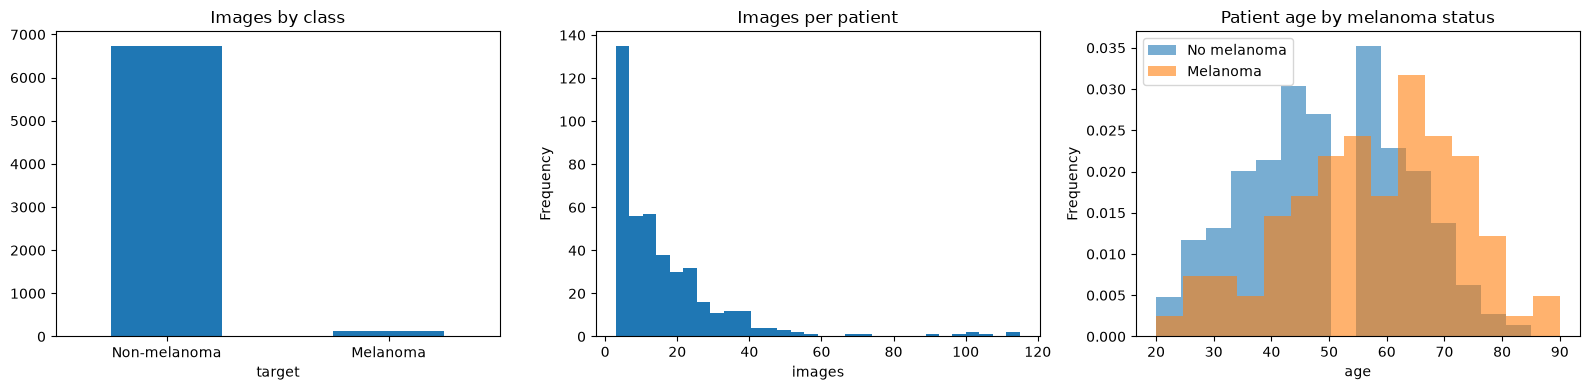

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

image_counts.rename({0: "Non-melanoma", 1: "Melanoma"}).plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Images by class")

patients["image_count"].plot.hist(bins=30, ax=axes[1])
axes[1].set(title="Images per patient", xlabel="images")

for label, name in [(0, "No melanoma"), (1, "Melanoma")]:
    patients.loc[patients["has_malignant"].eq(label), "age_approx"].astype(float).plot.hist(
        bins=15, alpha=0.6, density=True, ax=axes[2], label=name)
axes[2].set(title="Patient age by melanoma status", xlabel="age")
axes[2].legend()

plt.tight_layout()
plt.show()

## Anatomical site

Missing sites are labelled `unknown` by the cleaning step (and flagged in `site_missing`).

In [6]:
site_table = (
    clean.groupby("anatom_site_general_challenge")["target"]
    .agg(images="size", melanoma="sum")
    .assign(melanoma_percent=lambda d: d["melanoma"].astype(float) / d["images"] * 100)
    .sort_values("images", ascending=False)
)
display(site_table.round(1))

,images,melanoma,melanoma_percent
anatom_site_general_challenge,,,
torso,3440,54,1.6
lower extremity,1650,25,1.5
upper extremity,1066,23,2.2
head/neck,409,21,5.1
unknown,196,2,1.0
palms/soles,70,0,0.0
oral/genital,33,3,9.1
